# PD corporativa a horizontes de uno a cinco años (C02)

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 a 04 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este cuaderno puedes:

- leer los cinco archivos de horizonte de C02 y decir por qué sus tasas de evento no pueden leerse como una sola curva de PD acumulada;
- comparar los modelos de la escalera en cada horizonte con el AUC, su intervalo de DeLong y la brecha de sobreajuste, y recalcular la brecha y los valores p de DeLong desde los números versionados;
- recalcular un valor p de Hosmer-Lemeshow y una prueba de nivel de Jeffreys desde las tablas versionadas;
- leer la matriz de transferencia entre archivos y el modelo agrupado con la salvedad de traslape de empresas que limita a ambos.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La siguiente celda importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

El caso C02 es la PD de deudores corporativos a horizontes de uno a cinco años. Los datos son los "Polish companies bankruptcy data" de UCI (Tomczak, 2016; CC BY 4.0, clase de licencia `mirror-allowed`; https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data; DOI 10.24432/C5F600): cinco archivos de razones financieras de empresas manufactureras (64 razones por empresa) con una etiqueta de quiebra, cada uno para un horizonte de pronóstico. El pipeline ajustó la escalera de siete modelos en cada archivo con una muestra reservada bloqueada y estratificada, y sobre los cinco archivos apilados. Versionado:

- `data/derived/C02/h1.json` a `h5.json`: un archivo por horizonte, con la discriminación, la calibración, la verificación de sobreajuste y la estabilidad de los modelos, la comparación de cada retador con la tarjeta de puntaje, la transferencia entre archivos y la batería de pruebas.
- `data/derived/C02/pooled.json`: los cinco archivos apilados con un indicador de horizonte.
- `data/derived/C02/models-polish-horizons.json`: los archivos y el protocolo de división.

El zip crudo queda fuera del repositorio (`data/derived/C02/raw-sources.txt` registra su fila de fuente y su suma de verificación). La siguiente celda carga los archivos e imprime el evento de cada horizonte tal como lo define el archivo.

In [2]:
# Cargar los cinco archivos de horizonte, el archivo agrupado y el archivo de modelos de C02
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C02"
horizons = ["h1", "h2", "h3", "h4", "h5"]
docs = {h: json.loads((derived / f"{h}.json").read_text(encoding="utf-8")) for h in horizons}
pooled = json.loads((derived / "pooled.json").read_text(encoding="utf-8"))
protocol = json.loads((derived / "models-polish-horizons.json").read_text(encoding="utf-8"))["fit"]

LANG = "es"
# Los valores de luz del motor, nombrados en este idioma
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "s/l"}
for h in horizons:
    print(h, docs[h]["outputs"]["counts"]["event_definition"][LANG])
print("calculado por riskvalidation", {d["provenance"]["riskvalidation_version"] for d in docs.values()}, "| instalado", rv.__version__)


h1 Quiebra de la empresa dentro de 1 año de los estados financieros (la etiqueta de clase del archivo 5year.arff)
h2 Quiebra de la empresa dentro de 2 años de los estados financieros (la etiqueta de clase del archivo 4year.arff)
h3 Quiebra de la empresa dentro de 3 años de los estados financieros (la etiqueta de clase del archivo 3year.arff)
h4 Quiebra de la empresa dentro de 4 años de los estados financieros (la etiqueta de clase del archivo 2year.arff)
h5 Quiebra de la empresa dentro de 5 años de los estados financieros (la etiqueta de clase del archivo 1year.arff)
calculado por riskvalidation {'0.9.0'} | instalado 0.9.0


## Método

### Paso 1: cinco muestras, no una cohorte

Cada archivo es una muestra de empresas con las razones de un año y el estado de quiebra en un horizonte. Una lectura tentadora es tomar las cinco tasas de evento como la probabilidad acumulada de quiebra a uno, dos, tres, cuatro y cinco años, y leer de ellas una estructura temporal (la entrada de una pérdida crediticia esperada de vida completa). Esa lectura necesita una cohorte de empresas seguida durante cinco años, de modo que la proporción en quiebra solo pueda crecer con el horizonte. Los archivos son **muestras independientes de distintos años de pronóstico**, no una cohorte seguida en el tiempo, y la página de UCI no da identificador de empresa ni fecha. La decisión del producto (G22) es no leer ninguna estructura temporal de ellos. La primera verificación que permiten los datos es la que la lectura acumulada tendría que pasar: crecimiento estricto con el horizonte. La siguiente celda imprime los archivos, recalcula cada tasa de evento desde sus conteos, verifica el crecimiento e imprime la división de cada archivo (la muestra reservada es estratificada, así que su tasa sigue la del archivo).

In [3]:
# Imprimir los cinco archivos con sus tasas de evento y divisiones, y probar el crecimiento con el horizonte
print(f"{'horizonte':9s} {'años':>5s} {'filas':>7s} {'quiebras':>10s} {'tasa':>7s} {'entren.':>7s} {'calibr.':>9s} {'reservada':>10s} {'en reservada':>12s}")
rates = []
for h in horizons:
    o = docs[h]["outputs"]
    c, s = o["counts"], o["split"]
    rate = c["events"] / c["rows"]
    assert abs(rate - c["event_rate"]) < 1e-9
    rates.append(rate)
    print(f"{h:9s} {o['years']:5d} {c['rows']:7d} {c['events']:10d} {rate:7.4f} {s['train_rows']:7d} {s['calibration_rows']:9d} {s['holdout_rows']:10d} {s['holdout_events']:12d}")
print("estrictamente creciente con el horizonte:", si_no((np.diff(rates) > 0).all()))
print(docs["h3"]["outputs"]["term_structure_reason"][LANG])
print("efecto en la pérdida crediticia esperada versionado en el archivo:", docs["h3"]["outputs"]["impact_detail"]["ecl_lifetime_effect"])


horizonte  años   filas   quiebras    tasa entren.   calibr.  reservada en reservada
h1            1    5910        410  0.0694    3309       828       1773          123
h2            2    9792        515  0.0526    5483      1371       2938          155
h3            3   10503        495  0.0471    5881      1471       3151          149
h4            4   10173        400  0.0393    5696      1425       3052          120
h5            5    7027        271  0.0386    3934       984       2109           81
estrictamente creciente con el horizonte: no
Los cinco archivos son muestras independientes de distintos años de pronóstico, no una cohorte seguida en el tiempo, así que no se lee de ellos una PD acumulada. Sus tasas de evento (1y 0.0694, 2y 0.0526, 3y 0.0471, 4y 0.0393, 5y 0.0386) no crecen estrictamente con el horizonte, como lo haría una PD acumulada (decisión G22).
efecto en la pérdida crediticia esperada versionado en el archivo: None


### Paso 2: la escalera en cada horizonte

Los siete modelos son la misma escalera de los cuadernos 03 y 06: una línea base de una variable (P0), la tarjeta de puntaje WoE (P1), una regresión logística penalizada (P2a), árboles penalizados (P2b), una máquina de boosting explicable (P3) y dos modelos de árboles con boosting (P4). El AUC con su intervalo de DeLong del 95% (DeLong, DeLong y Clarke-Pearson, 1988) está versionado para la muestra reservada de cada archivo, y el coeficiente de Gini es $2\,\mathrm{AUC} - 1$. La siguiente celda verifica esa identidad en cada par versionado e imprime el AUC por modelo y horizonte, con el intervalo de la tarjeta de puntaje; la figura dibuja las líneas. Una muestra reservada de 81 a 155 quiebras por archivo da intervalos anchos, que es el principal límite de este caso.

In [4]:
# Imprimir el AUC de cada modelo en cada horizonte y verificar la identidad del Gini
def rung_of(entry):
    return entry["model_id"].split("-", 1)[1]


rungs = [rung_of(x) for x in docs["h1"]["outputs"]["rungs"]]
auc = {h: {rung_of(x): x["discrimination"] for x in docs[h]["outputs"]["rungs"]} for h in horizons}
gini_gap = max(abs(d["gini"] - (2 * d["auc"] - 1)) for h in horizons for d in auc[h].values())
print("mayor brecha de la identidad del Gini:", f"{gini_gap:.1e}")
print(f"{'modelo':14s}" + "".join(f"{h:>8s}" for h in horizons))
for r in rungs:
    print(f"{r:14s}" + "".join(f"{auc[h][r]['auc']:8.3f}" for h in horizons))
print()
print(f"{'P1-scorecard':14s} intervalo del 95%: " + " | ".join(f"{h} {auc[h]['P1-scorecard']['auc_ci']['lo']:.2f}-{auc[h]['P1-scorecard']['auc_ci']['hi']:.2f}" for h in horizons))


mayor brecha de la identidad del Gini: 0.0e+00
modelo              h1      h2      h3      h4      h5
P0-single        0.813   0.670   0.612   0.674   0.743
P1-scorecard     0.911   0.810   0.839   0.792   0.728
P2a-l1           0.912   0.835   0.867   0.812   0.758
P2b-pltr         0.934   0.904   0.890   0.897   0.903
P3-ebm           0.954   0.922   0.898   0.901   0.932
P4-lightgbm      0.952   0.923   0.925   0.912   0.943
P4-xgboost       0.941   0.912   0.901   0.889   0.927

P1-scorecard   intervalo del 95%: h1 0.89-0.93 | h2 0.77-0.85 | h3 0.80-0.88 | h4 0.75-0.84 | h5 0.67-0.78


La figura dibuja el AUC de cada modelo frente al horizonte.

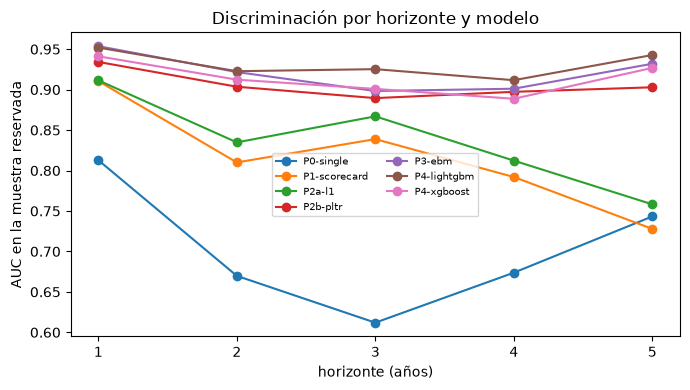

In [5]:
# Dibujar el AUC de cada modelo frente al horizonte
fig, ax = plt.subplots(figsize=(7, 4))
for r in rungs:
    ax.plot([docs[h]["outputs"]["years"] for h in horizons], [auc[h][r]["auc"] for h in horizons], marker="o", label=r)
ax.set_xlabel("horizonte (años)")
ax.set_ylabel("AUC en la muestra reservada")
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_title("Discriminación por horizonte y modelo")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()


### Paso 3: la brecha de sobreajuste

Un modelo que ordena bien sobre los datos en que se ajustó y peor sobre datos nuevos ha memorizado ruido. La verificación versionada compara el AUC del tramo de entrenamiento con el AUC de la muestra reservada; la brecha se marca cuando excede una tolerancia de 0,05 puntos de AUC, una convención del producto (la investigación no da valor; la tolerancia es de uno y medio a tres errores estándar de un AUC con estos tamaños de muestra reservada). La siguiente celda recalcula la brecha y la marca de cada modelo y horizonte desde los AUC versionados de entrenamiento y de la muestra reservada, y señala los marcados.

In [6]:
# Recalcular la brecha de sobreajuste y la marca de cada modelo y horizonte desde los AUC versionados de entrenamiento y de la muestra reservada
tolerance = docs["h1"]["outputs"]["parameters"][0]["value"]
print("tolerancia:", tolerance, "| '*' marca una brecha sobre la tolerancia")
print(f"{'modelo':14s}" + "".join(f"{h:>9s}" for h in horizons))
flags_agree = []
for x in docs["h1"]["outputs"]["rungs"]:
    r = rung_of(x)
    line = f"{r:14s}"
    for h in horizons:
        o = next(e for e in docs[h]["outputs"]["rungs"] if rung_of(e) == r)["overfit"]
        gap = o["train_auc"] - o["holdout_auc"]
        flagged = gap > tolerance
        flags_agree.append(flagged == o["flag"])
        line += f"{gap:8.3f}{'*' if flagged else ' '}"
    print(line)
print("las marcas son iguales a las versionadas:", si_no(all(flags_agree)))


tolerancia: 0.05 | '*' marca una brecha sobre la tolerancia
modelo               h1       h2       h3       h4       h5
P0-single       -0.027    0.049    0.050   -0.016   -0.005 
P1-scorecard     0.005    0.033    0.018    0.065*   0.092*
P2a-l1           0.023    0.029    0.015    0.067*   0.077*
P2b-pltr         0.039    0.071*   0.092*   0.085*   0.079*
P3-ebm           0.039    0.053*   0.081*   0.075*   0.062*
P4-lightgbm      0.048    0.077*   0.074*   0.088*   0.057*
P4-xgboost       0.055*   0.073*   0.095*   0.102*   0.063*
las marcas son iguales a las versionadas: sí


### Paso 4: los retadores frente a la tarjeta de puntaje

Para cada horizonte el archivo compara cada retador con la tarjeta de puntaje (la campeona): la diferencia de AUC con su intervalo de DeLong, el valor p, el cambio del puntaje de Brier y la proporción de empresas cuyo grado cambia entre ambos. El intervalo de DeLong es $\Delta \pm z_{0,975}\,\mathrm{SE}$, así que el error estándar se recupera del intervalo y el valor p sale de la misma ley normal que en el cuaderno 03:

$$\mathrm{SE} = \frac{\mathrm{hi} - \mathrm{lo}}{2 z_{0,975}}, \qquad z = \frac{\Delta}{\mathrm{SE}}, \qquad p = 2\,(1 - \Phi(|z|))$$

La siguiente celda lo hace para las 25 comparaciones (cinco horizontes por cinco retadores) e imprime la diferencia, el valor p recalculado, el versionado y la proporción de empresas que cambian de grado.

In [7]:
# Recuperar el error estándar de cada intervalo de DeLong y recalcular el valor p de cada comparación de retador
z975 = stats.norm.ppf(0.975)
print(f"{'horizonte':8s} {'retador':12s} {'dif. AUC':>10s} {'p recalculado':>16s} {'p versionado':>14s} {'cambios de grado':>18s}")
gap_max = 0.0
for h in horizons:
    for c in docs[h]["outputs"]["challenger"]:
        ci = c["auc_diff_ci"]
        se = (ci["hi"] - ci["lo"]) / (2 * z975)
        z = c["auc_diff"] / se
        p = 2 * stats.norm.sf(abs(z))
        gap_max = max(gap_max, abs(np.log10(p) - np.log10(c["delong_p_value"])))
        print(f"{h:8s} {c['challenger'].split('-', 1)[1]:12s} {c['auc_diff']:10.4f} {p:16.3g} {c['delong_p_value']:14.3g} {c['grade_disagreement_share']:18.3f}")
print("mayor brecha entre los dos valores p, en órdenes de magnitud:", round(gap_max, 4))


horizonte retador        dif. AUC    p recalculado   p versionado   cambios de grado
h1       P2a-l1           0.0009            0.897          0.897              0.186
h1       P2b-pltr         0.0237          0.00256        0.00256              0.356
h1       P3-ebm           0.0431         7.45e-05       7.45e-05              0.394
h1       P4-lightgbm      0.0414         1.79e-06       1.79e-06              0.397
h1       P4-xgboost       0.0306          0.00113        0.00113              0.404
h2       P2a-l1           0.0248         0.000152       0.000152              0.129
h2       P2b-pltr         0.0936         6.46e-11       6.46e-11              0.500
h2       P3-ebm           0.1117         1.24e-14       1.24e-14              0.500
h2       P4-lightgbm      0.1128         6.26e-16       6.26e-16              0.495
h2       P4-xgboost       0.1023         3.79e-14       3.79e-14              0.497
h3       P2a-l1           0.0282          0.00157        0.00157           

### Paso 5: calibración

Dos números versionados por modelo y horizonte hablan de calibración: el estadístico de Hosmer-Lemeshow con sus grados de libertad y su valor p (cuaderno 03), y la prueba de nivel sobre toda la muestra reservada. La siguiente celda recalcula el valor p de Hosmer-Lemeshow desde su estadístico y sus grados de libertad con la ley chi-cuadrado, imprime las luces que la política da a los valores p de HL de cada modelo y horizonte, y llama a la prueba de Jeffreys del motor sobre la tarjeta de puntaje de cada horizonte, desde el tamaño de la muestra reservada, sus quiebras y la PD media de sus tramos de confiabilidad, para compararla con la fila de nivel versionada.

In [8]:
# Recalcular los valores p de Hosmer-Lemeshow, mostrar sus luces y llamar a la prueba de Jeffreys sobre la tarjeta de puntaje de cada horizonte
from riskvalidation.validation import pd_jeffreys

policy = rv.default_policy()


def committed_row(h, test_id, rung):
    return next(t for t in docs[h]["tests"] if t["test_id"] == test_id and t["model_id"] == f"{h}-{rung}" and t["segment"] == "portfolio")


gap_max = 0.0
print(f"{'modelo':14s}" + "".join(f"{h:>13s}" for h in horizons))
for r in rungs:
    line = f"{r:14s}"
    for h in horizons:
        hl = next(e for e in docs[h]["outputs"]["rungs"] if rung_of(e) == r)["calibration"]["hosmer_lemeshow"]
        p = stats.chi2.sf(hl["statistic"], hl["df"])
        gap_max = max(gap_max, abs(p - hl["p_value"]))
        line += f"{p:9.4f} {LIGHT[committed_row(h, 'pd.hosmer_lemeshow', r)['light']][:3]:>3s}"
    print(line)
print("mayor brecha con el valor p de HL versionado:", f"{gap_max:.1e}")
print()
for h in horizons:
    o = docs[h]["outputs"]
    x = next(e for e in o["rungs"] if rung_of(e) == "P1-scorecard")
    mean_pd = sum(b["n"] * b["pd"] for b in x["reliability"]) / sum(b["n"] for b in x["reliability"])
    jef = pd_jeffreys(n=o["split"]["holdout_rows"], d=o["split"]["holdout_events"], pd=mean_pd, policy=policy, model_id=f"{h}-P1-scorecard", segment="portfolio")
    row = committed_row(h, "pd.jeffreys", "P1-scorecard")
    print(f"{h} P1: N {jef.n} D {jef.n_events} PD media {mean_pd:.4f} | p Jeffreys {jef.p_value:.4f} | versionado {row['p_value']:.4f} | {LIGHT[row['light']]}")


modelo                   h1           h2           h3           h4           h5
P0-single        0.0000 roj   0.0000 roj   0.0000 roj   0.0000 roj   0.0000 roj
P1-scorecard     0.3511 ver   0.8203 ver   0.0705 ver   0.0258 ámb   0.0005 roj
P2a-l1           0.0267 ámb   0.5706 ver   0.1510 ver   0.0003 roj   0.0552 ver
P2b-pltr         0.5956 ver   0.0000 roj   0.0108 ámb   0.0065 roj   0.0000 roj
P3-ebm           0.7663 ver   0.0380 ámb   0.0000 roj   0.1212 ver   0.2226 ver
P4-lightgbm      0.0787 ver   0.0000 roj   0.1065 ver   0.0008 roj   0.6778 ver
P4-xgboost       0.0028 roj   0.0000 roj   0.0000 roj   0.0013 roj   0.5702 ver
mayor brecha con el valor p de HL versionado: 0.0e+00

h1 P1: N 1773 D 123 PD media 0.0748 | p Jeffreys 0.8086 | versionado 0.8086 | verde
h2 P1: N 2938 D 155 PD media 0.0523 | p Jeffreys 0.4518 | versionado 0.4518 | verde
h3 P1: N 3151 D 149 PD media 0.0462 | p Jeffreys 0.3835 | versionado 0.3835 | verde
h4 P1: N 3052 D 120 PD media 0.0387 | p Jeffreys 0.42

### Paso 6: la misma tarjeta de puntaje en otro archivo

El archivo de cada horizonte versiona un bloque de **transferencia**: un modelo ajustado en el tramo de entrenamiento de un archivo y puntuado en la muestra reservada de otro. Es una verificación de robustez tentadora, y el archivo la rotula exploratoria por una razón. La página de UCI no da identificador de empresa, así que la misma empresa puede aparecer en varios archivos (una empresa observada en el tercer año y otra vez en el quinto), y un modelo ajustado en un archivo puede puntuarse sobre empresas que ha visto en parte. Cualquier AUC de transferencia puede por eso estar inflado, y no se hace ninguna afirmación fuera del tiempo. La diagonal es el modelo puntuado sobre su propia muestra reservada y debe ser igual al AUC del paso 2. La siguiente celda construye la matriz de la tarjeta de puntaje desde los cinco archivos, verifica la diagonal y la dibuja.

la diagonal es igual al AUC de la muestra reservada del paso 2: sí
exploratorio | Un escalón ajustado en el tramo de entrenamiento de un archivo y puntuado en la muestra reservada de otro. El traslape de empresas entre archivos se desconoce, de modo que el AUC de traslado puede estar inflado por empresas repetidas; el bloque es exploratorio y no se afirma nada fuera del tiempo.
ajustado en     puntuado en h1  puntuado en h2  puntuado en h3  puntuado en h4  puntuado en h5
h1                       0.911           0.801           0.787           0.759           0.836
h2                       0.899           0.810           0.812           0.771           0.861
h3                       0.881           0.839           0.839           0.760           0.879
h4                       0.862           0.799           0.814           0.792           0.875
h5                       0.829           0.719           0.745           0.644           0.728


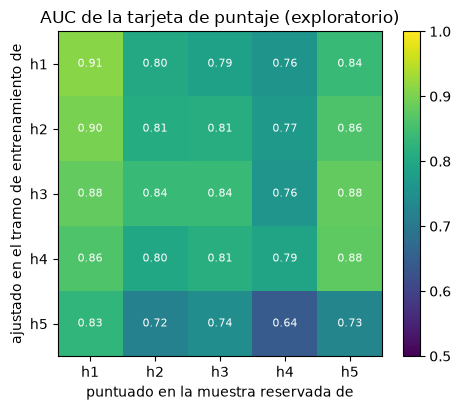

In [9]:
# Construir la matriz de transferencia de la tarjeta de puntaje, verificar su diagonal contra el paso 2 y dibujarla
matrix = np.zeros((5, 5))
for fitted, h in enumerate(horizons):
    for cell in docs[h]["outputs"]["transfer"]["cells"]:
        if cell["rung"] == "P1":
            matrix[fitted, cell["scored_on_years"] - 1] = cell["auc"]
diagonal = np.array([auc[h]["P1-scorecard"]["auc"] for h in horizons])
print("la diagonal es igual al AUC de la muestra reservada del paso 2:", si_no(np.allclose(np.diag(matrix), diagonal)))
print({"exploratory": "exploratorio"}[docs["h1"]["outputs"]["transfer"]["label"]], "|", docs["h1"]["outputs"]["transfer"]["reason"][LANG])
print(f"{'ajustado en':14s}" + "".join(f"{'puntuado en h' + str(j + 1):>16s}" for j in range(5)))
for i in range(5):
    print(f"{'h' + str(i + 1):14s}" + "".join(f"{matrix[i, j]:16.3f}" for j in range(5)))

fig, ax = plt.subplots(figsize=(5, 4.2))
image = ax.imshow(matrix, vmin=0.5, vmax=1.0, cmap="viridis")
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", color="white", fontsize=8)
ax.set_xticks(range(5))
ax.set_xticklabels([f"h{j + 1}" for j in range(5)])
ax.set_yticks(range(5))
ax.set_yticklabels([f"h{i + 1}" for i in range(5)])
ax.set_xlabel("puntuado en la muestra reservada de")
ax.set_ylabel("ajustado en el tramo de entrenamiento de")
ax.set_title("AUC de la tarjeta de puntaje (exploratorio)")
fig.colorbar(image, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()


### Paso 7: los cinco archivos apilados

El archivo agrupado apila los cinco archivos con un indicador de horizonte, de modo que un solo modelo ve 43.405 empresas-año. Tiene más datos y un intervalo más estrecho, y lleva la misma salvedad completa: no se sabe si una empresa se repite entre los archivos, así que una empresa puede estar en el tramo de entrenamiento y en la muestra reservada bajo horizontes distintos. La siguiente celda imprime los conteos agrupados, la salvedad versionada y el AUC de cada modelo frente a su promedio por horizonte, y la variable única que la línea base P0 eligió en el archivo agrupado.

In [10]:
# Imprimir los conteos y la salvedad agrupados, y el AUC agrupado frente al promedio por horizonte
po = pooled["outputs"]
print("empresas-año:", po["counts"]["rows"], "| quiebras:", po["counts"]["events"], "| tasa:", round(po["counts"]["event_rate"], 4), "| reservada:", po["split"]["holdout_rows"], "/", po["split"]["holdout_events"])
print("variable única de la línea base P0:", pooled["model"][0]["title"][LANG])
print(po["firm_overlap_caveat"][LANG])
print(f"{'modelo':14s} {'AUC agrupado':>16s} {'media de cinco horizontes':>28s}")
for x in po["rungs"]:
    r = rung_of(x)
    print(f"{r:14s} {x['discrimination']['auc']:16.3f} {np.mean([auc[h][r]['auc'] for h in horizons]):28.3f}")


empresas-año: 43405 | quiebras: 2091 | tasa: 0.0482 | reservada: 13023 / 628
variable única de la línea base P0: Una variable (Attr27_missing)
Los cinco archivos se apilan con un indicador de horizonte. La página de UCI no da identificador de empresa ni fecha, de modo que no se sabe si una empresa aparece en varios archivos (SIN VERIFICAR, 08 l.855-856). Ningún vector de variables se repite entre dos archivos, pero las razones de una empresa cambian de un año al siguiente, así que eso no es evidencia de que las empresas no se repitan. Un puntaje agrupado puede por tanto estar favorecido por empresas repetidas.
modelo             AUC agrupado    media de cinco horizontes
P0-single                 0.652                        0.702
P1-scorecard              0.865                        0.816
P2a-l1                    0.882                        0.837
P2b-pltr                  0.917                        0.906
P3-ebm                    0.945                        0.921
P4-lightgbm     

## Resultados

- **Sin estructura temporal.** Las cinco tasas de evento bajan con el horizonte (6,9%, 5,3%, 4,7%, 3,9%, 3,9%) donde una PD acumulada subiría: los archivos son muestras distintas, así que no se calcula la pérdida crediticia esperada bajo los cinco horizontes (el efecto versionado es nulo, con la razón). Una estimación de vida completa necesita una cohorte seguida en el tiempo, que estos datos no pueden dar.
- **El ordenamiento es fuerte y desigual.** Con 64 razones financieras la tarjeta de puntaje llega a un AUC de 0,91 en h1 y 0,73 en h5; los modelos con boosting llegan a 0,94 a 0,95 en h1 y 0,93 a 0,94 en h5. Los intervalos son anchos (el de la tarjeta de puntaje en h5 va de 0,67 a 0,78, con 81 quiebras en la muestra reservada).
- **La tarjeta de puntaje sobreajusta en el horizonte más largo.** Su brecha entre entrenamiento y muestra reservada es 0,005 en h1, 0,065 en h4 y 0,092 en h5, sobre la tolerancia de 0,05 en los dos últimos, y la misma marca aparece en otros modelos en varios horizontes: con pocas quiebras un modelo flexible aprende el tramo de entrenamiento. Las marcas recalculadas son iguales a las versionadas.
- **Los retadores ordenan mejor, no siempre de forma significativa.** En h1 la regresión penalizada empata con la tarjeta de puntaje (DeLong p 0,90), mientras que los árboles, la máquina de boosting explicable y los dos modelos con boosting ganan 0,02 a 0,04 puntos de AUC (p bajo 0,003); en h5 los cinco son significativos. Los valores p de DeLong recalculados son iguales a los versionados a la precisión de los intervalos versionados. El desacuerdo de grados (hasta cerca del 50% de las empresas) es el costo práctico de cambiar el modelo.
- **La calibración es mixta.** La prueba de nivel (Jeffreys) es verde para la tarjeta de puntaje en todos los horizontes, y los valores p de Hosmer-Lemeshow se recalculan exactamente desde sus estadísticos; algunos modelos están en rojo en la prueba de ajuste en algún horizonte (la línea base de una variable en todos los horizontes), como explicó el cuaderno 03 sobre el nivel y el ajuste.
- **La matriz de transferencia no puede leerse como robustez.** Varias celdas fuera de la diagonal superan a la diagonal: la tarjeta de puntaje ajustada en h4 puntúa 0,875 en la muestra reservada de h5, sobre el 0,728 de la tarjeta de puntaje ajustada en el propio h5. Con traslape de empresas desconocido, un AUC de transferencia alto puede venir tanto de empresas repetidas como de un modelo que generaliza. El modelo agrupado llega a 0,97 con LightGBM, el mismo límite amplificado por la muestra mayor, y la línea base de una variable agrupada eligió el indicador de que la razón Attr27 falta, no una razón misma (AUC 0,652).

Lo que este cuaderno no muestra: el ajuste de los modelos en sí (`data-pipeline/pipeline/cases/c02/` del pipeline), una calificación de riesgo corporativo en otro país, ni una prueba fuera del tiempo: los archivos no tienen fecha, y el caso declara que no se hace ninguna afirmación fuera del tiempo (`out_of_time_claim` falso).

## Resumen

- Cinco archivos de distintos años de pronóstico son cinco muestras, no una cohorte: sus tasas de evento no tienen por qué crecer con el horizonte, y de ellos no se lee estructura temporal ni pérdida de vida completa.
- La escalera se compara en cada horizonte con el AUC y su intervalo de DeLong; la brecha de sobreajuste marca el horizonte más largo, donde pocas quiebras se encuentran con 64 razones.
- Un valor p versionado puede recalcularse desde los números a su lado: el p de DeLong desde el intervalo, el p de Hosmer-Lemeshow desde su estadístico, la prueba de Jeffreys desde el tamaño, los incumplimientos y la PD media.
- Una transferencia entre archivos y un modelo agrupado son exploratorios: sin identificador de empresa no pueden llamarse fuera de muestra.

**Qué probar después.** Toma el horizonte con la tarjeta de puntaje más débil (h5) y lee sus tramos de confiabilidad en `h5.json` frente al modelo con mejor calibración; luego continúa con el cuaderno 06, que ubica a los retadores de C01 en el estado del arte.

## Referencias

- Tomczak, S. (2016), Polish Companies Bankruptcy, UCI Machine Learning Repository (CC BY 4.0), https://doi.org/10.24432/C5F600 (la atribución registrada en `data/derived/C02/raw-sources.txt`). https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data
- DeLong, E. R., DeLong, D. M. y Clarke-Pearson, D. L. (1988), Comparing the areas under two or more correlated receiver operating characteristic curves: a nonparametric approach, Biometrics 44(3). https://doi.org/10.2307/2531595
- Hosmer, D. W. y Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Brown, L. D., Cai, T. T. y DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, Anexo 1 (sección 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf